# Этап 5. Расчёт метрик

В социальном проекте нет LTV, CAC и Retention, поэтому этап адаптирован: вместо метрик клиентов считаем метрики регионов, которые отвечают на вопросы заказчика (Минэкономики).

| Метрика | Вопрос | Гипотеза |
|---|---|---|
| CAGR доходов (номинальный и реальный) | Где доходы растут быстрее? | — |
| σ-конвергенция: коэффициент вариации, разрыв max/min | Сокращается ли неравенство между регионами? | H3 |
| β-конвергенция: рост против стартового уровня | Догоняют ли бедные регионы богатых? | H3 |
| Доход / прожиточный минимум, сдвиг рейтинга | Меняется ли картина с поправкой на цены? | H4 |
| Индекс качества жизни | Где жить лучше всего, если смотреть не только на деньги? | — |

## Оглавление
1. [Настройка и загрузка](#setup)
2. [CAGR доходов](#cagr)
3. [H3: сокращается ли разрыв](#h3)
4. [H4: доход с поправкой на прожиточный минимум](#h4)
5. [Индекс качества жизни](#qol)
6. [Сохранение метрик](#save)
7. [Выводы этапа](#summary)

<a id="setup"></a>
## 1. Настройка и загрузка

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({
    "figure.figsize": (9, 4.5), "font.size": 10,
    "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#b4b2a9", "grid.color": "#e6e4dd",
})
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)

BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
GRAY, LIGHT, INK, MUTED = "#b4b2a9", "#d9d7cf", "#0b0b0b", "#52514e"
SEQ = LinearSegmentedColormap.from_list("seq_blue", ["#e8f1fb", "#9cc2ef", "#2a78d6", "#123e73"])

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data" / "processed"
IMAGES = ROOT / "images"
IMAGES.mkdir(exist_ok=True)

units = pd.read_csv(DATA / "panel_units_clean.csv")
regions = pd.read_csv(DATA / "panel_regions_clean.csv")
FIRST, LAST = int(units.year.min()), int(units.year.max())
N_YEARS = LAST - FIRST

SHORT = {   # короткие подписи для графиков
    "Южно-Казахстанская (Туркестанская + Шымкент)": "ЮКО (Туркестанская + Шымкент)",
    "Восточно-Казахстанская + Абай": "ВКО + Абай",
    "Западно-Казахстанская": "ЗКО",
    "Северо-Казахстанская": "СКО",
}
units["label"] = units.unit_name.replace(SHORT)
print(f"16 сопоставимых единиц, {FIRST}–{LAST}; 20 регионов в срезе {LAST} г.")

16 сопоставимых единиц, 2015–2024; 20 регионов в срезе 2024 г.


<a id="cagr"></a>
## 2. CAGR доходов

**CAGR** (среднегодовой темп роста) = (Доход₂₀₂₄ / Доход₂₀₁₅)^(1/9) − 1.
- **Номинальный** — рост дохода в тенге.
- **Реальный** — рост отношения «доход / прожиточный минимум», то есть рост покупательной способности. Прожиточный минимум растёт вместе с ценами, поэтому реальный CAGR очищен от инфляции (грубо: ПМ — это не полный индекс цен, а стоимость минимальной корзины).

⚠️ Отношение к ПМ в 2018 г. проседает во всех регионах из-за смены методики ПМ (этап 3). Это одинаково занижает реальный рост всех регионов, поэтому **сравнивать регионы между собой** можно, а абсолютное значение реального CAGR — с осторожностью.

In [2]:
def cagr(start, end, years=N_YEARS):
    return ((end / start) ** (1 / years) - 1) * 100

inc = units.pivot(index="label", columns="year", values="income_pc")
real = units.pivot(index="label", columns="year", values="income_to_subsistence")

growth = pd.DataFrame({
    f"доход {FIRST}": inc[FIRST],
    f"доход {LAST}": inc[LAST],
    "CAGR номинальный, %": cagr(inc[FIRST], inc[LAST]),
    f"доход/ПМ {FIRST}": real[FIRST],
    f"доход/ПМ {LAST}": real[LAST],
    "CAGR реальный, %": cagr(real[FIRST], real[LAST]),
}).sort_values("CAGR номинальный, %", ascending=False)

kz_inc = {y: np.average(g.income_pc, weights=g.population) for y, g in units.groupby("year")}
kz_cagr = cagr(kz_inc[FIRST], kz_inc[LAST])
print(f"В среднем по стране: {kz_inc[FIRST] / 1000:.0f} → {kz_inc[LAST] / 1000:.0f} тыс. тенге, CAGR {kz_cagr:.1f}% в год")
growth.round(2)

В среднем по стране: 66 → 212 тыс. тенге, CAGR 13.9% в год


,доход 2015,доход 2024,"CAGR номинальный, %",доход/ПМ 2015,доход/ПМ 2024,"CAGR реальный, %"
label,,,,,,
ВКО + Абай,55392.0,209726.0,15.94,2.81,4.00,4.01
Костанайская,55399.0,204267.0,15.60,3.02,4.17,3.66
Карагандинская + Ұлытау,66841.0,242961.0,15.42,3.56,4.91,3.62
ЮКО (Туркестанская + Шымкент),35830.0,127949.0,15.19,1.97,2.70,3.55
СКО,54653.0,194843.0,15.17,3.00,3.90,2.93
Жамбылская,43143.0,150627.0,14.90,2.44,3.13,2.83
Павлодарская,66488.0,229108.0,14.74,3.77,4.64,2.36
Акмолинская,56579.0,187922.0,14.27,3.10,3.75,2.13
Актюбинская,60921.0,191514.0,13.57,3.38,4.13,2.24


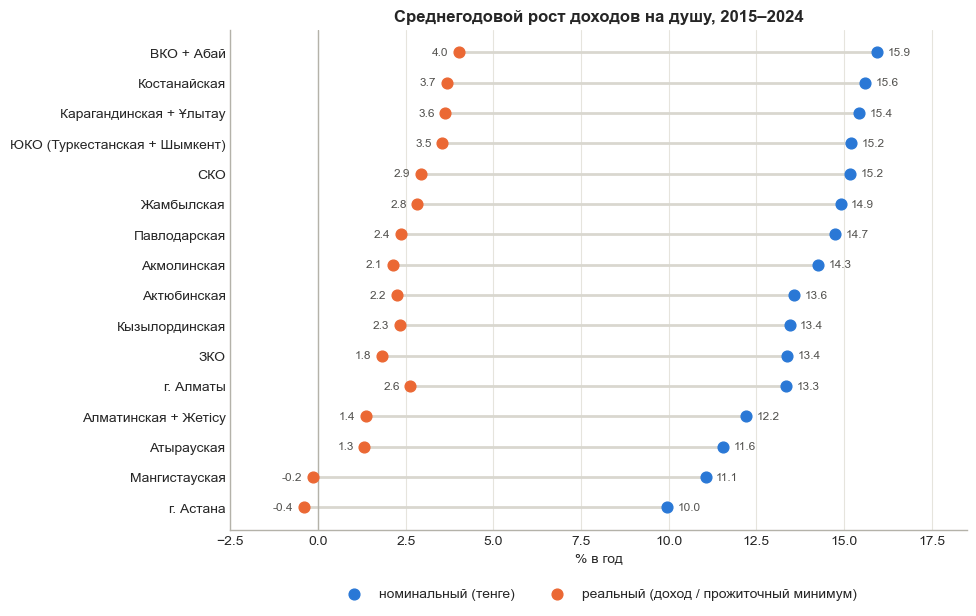

In [3]:
g = growth.sort_values("CAGR номинальный, %")
y = np.arange(len(g))

fig, ax = plt.subplots(figsize=(9.5, 6.5))
ax.hlines(y, g["CAGR реальный, %"], g["CAGR номинальный, %"], color=LIGHT, lw=2, zorder=1)
ax.scatter(g["CAGR номинальный, %"], y, color=BLUE, s=60, zorder=3, label="номинальный (тенге)")
ax.scatter(g["CAGR реальный, %"], y, color=ORANGE, s=60, zorder=3, label="реальный (доход / прожиточный минимум)")
for yi, (nom, rl) in enumerate(zip(g["CAGR номинальный, %"], g["CAGR реальный, %"])):
    ax.text(nom + 0.3, yi, f"{nom:.1f}", va="center", fontsize=8.5, color=MUTED)
    ax.text(rl - 0.3, yi, f"{rl:.1f}", va="center", ha="right", fontsize=8.5, color=MUTED)
ax.axvline(0, color=GRAY, lw=1)
ax.set_yticks(y, g.index)
ax.set_xlim(-2.5, 18.5)
ax.set_xlabel("% в год")
ax.set_title(f"Среднегодовой рост доходов на душу, {FIRST}–{LAST}")
ax.grid(axis="y", visible=False)
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.09), ncol=2)
fig.savefig(IMAGES / "06_cagr_income.png", dpi=150, bbox_inches="tight")
plt.show()

**Вывод:**
- Номинально доходы росли на 10–16% в год (в среднем по стране около 14%), реально — от −0,4% до +4% в год. Большая часть номинального роста съедена ростом цен.
- **Быстрее всех растут** ВКО + Абай, Костанайская, Карагандинская + Ұлытау и самая бедная в 2015 г. ЮКО: реальный рост 3,5–4% в год.
- **Медленнее всех — лидеры 2015 г.**: Астана (−0,4% реально) и Мангистауская (−0,2%). В Астане покупательная способность дохода за 9 лет не выросла: доходы росли примерно так же, как прожиточный минимум. Высокий старт и быстрый приток населения (этап 3) делают столицу «дорогой».

<a id="h3"></a>
## 3. H3: сокращается ли разрыв между регионами

**σ-конвергенция** — уменьшается ли разброс доходов. Считаем три меры:
- **коэффициент вариации** (CV = σ / μ) — все регионы равны;
- **взвешенный CV** — регионы весят по численности населения (вклад Алматы с 2,2 млн жителей больше, чем у Ұлытау с 0,2 млн);
- **разрыв max/min** — во сколько раз самый богатый регион богаче самого бедного.

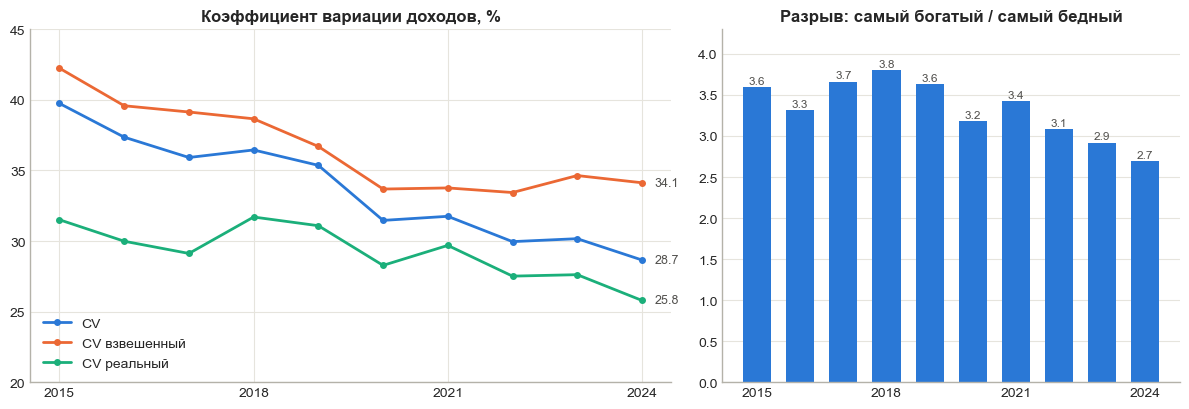

Тренд CV: -1.20 п. п. в год, p-value = 0.0000


,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
"CV, %",39.75,37.36,35.92,36.45,35.36,31.46,31.75,29.96,30.17,28.65
"CV взвешенный, %",42.24,39.58,39.14,38.66,36.70,33.68,33.76,33.44,34.64,34.13
"CV реальный, %",31.51,29.99,29.12,31.70,31.08,28.27,29.69,27.51,27.62,25.79
разрыв max/min,3.60,3.31,3.66,3.80,3.63,3.18,3.43,3.08,2.92,2.69


In [4]:
def weighted_cv(x, w):
    mean = np.average(x, weights=w)
    return np.sqrt(np.average((x - mean) ** 2, weights=w)) / mean * 100

sigma = pd.DataFrame({
    "CV, %": units.groupby("year").income_pc.agg(lambda x: x.std(ddof=0) / x.mean() * 100),
    "CV взвешенный, %": {y: weighted_cv(g.income_pc, g.population) for y, g in units.groupby("year")},
    "CV реальный, %": units.groupby("year").income_to_subsistence.agg(lambda x: x.std(ddof=0) / x.mean() * 100),
    "разрыв max/min": units.groupby("year").income_pc.agg(lambda x: x.max() / x.min()),
})

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1.4, 1]})
ax = axes[0]
for col, color in [("CV, %", BLUE), ("CV взвешенный, %", ORANGE), ("CV реальный, %", AQUA)]:
    ax.plot(sigma.index, sigma[col], color=color, lw=2, marker="o", ms=4, label=col.replace(", %", ""))
    ax.text(LAST + 0.2, sigma[col].iloc[-1], f"{sigma[col].iloc[-1]:.1f}", va="center", fontsize=9, color=MUTED)
ax.set_title("Коэффициент вариации доходов, %")
ax.set_ylim(20, 45)
ax.set_xticks(sigma.index[::3])
ax.legend(frameon=False, loc="lower left")

ax = axes[1]
ax.bar(sigma.index, sigma["разрыв max/min"], color=BLUE, width=0.65)
for yr, v in sigma["разрыв max/min"].items():
    ax.text(yr, v + 0.04, f"{v:.1f}", ha="center", fontsize=8.5, color=MUTED)
ax.set_title("Разрыв: самый богатый / самый бедный")
ax.set_ylim(0, 4.3)
ax.set_xticks(sigma.index[::3])
ax.grid(axis="x", visible=False)
plt.tight_layout()
fig.savefig(IMAGES / "07_sigma_convergence.png", dpi=150, bbox_inches="tight")
plt.show()

trend = stats.linregress(sigma.index, sigma["CV, %"])
print(f"Тренд CV: {trend.slope:+.2f} п. п. в год, p-value = {trend.pvalue:.4f}")
sigma.round(2).T

**σ-конвергенция есть.** Коэффициент вариации снизился с 39,7% до 28,7%, разрыв между крайними регионами — с 3,6 до 2,7 раза. Тренд значимый: CV падает примерно на 1,2 п. п. в год. Реальные доходы (доход / ПМ) тоже сближаются: 31,5% → 25,8%.

Но **взвешенный по населению CV** снизился меньше (42,2% → 34,1%) и с 2020 г. перестал падать. Регионы в целом сближаются, но два крупнейших мегаполиса держат отрыв, а в них живёт почти пятая часть населения. Для типичного жителя страны неравенство сокращается медленнее, чем для «типичного региона».

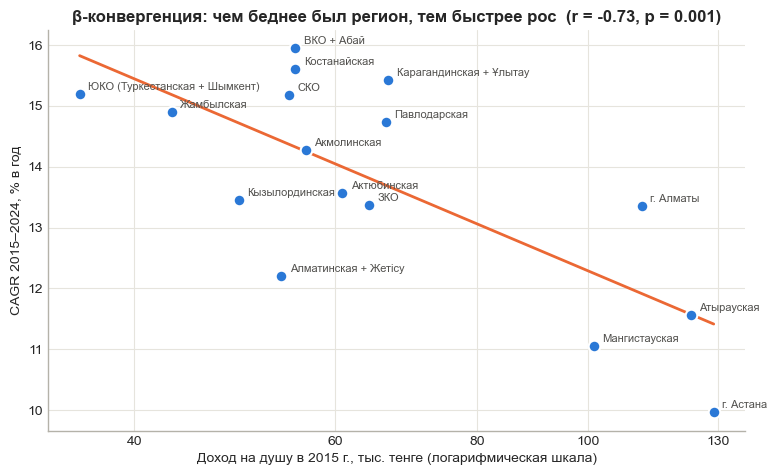

Наклон: -3.44 → регион, который в 2015 г. был на 10% беднее, рос быстрее на 0.33 п. п. в год
Пирсон r = -0.73 (p = 0.0014); Спирмен ρ = -0.54 (p = 0.030)


In [5]:
start = np.log(inc[FIRST])
growth_rate = growth.loc[inc.index, "CAGR номинальный, %"]
beta = stats.linregress(start, growth_rate)
rho_b, p_b = stats.spearmanr(start, growth_rate)

fig, ax = plt.subplots(figsize=(9, 5.2))
ax.scatter(inc[FIRST] / 1000, growth_rate, s=70, color=BLUE, edgecolor="white", linewidth=1.5, zorder=3)
xs = np.linspace(start.min(), start.max(), 50)
ax.plot(np.exp(xs) / 1000, beta.intercept + beta.slope * xs, color=ORANGE, lw=2, zorder=2)
for name in inc.index:
    ax.annotate(name, (inc.loc[name, FIRST] / 1000, growth_rate[name]), xytext=(6, 3),
                textcoords="offset points", fontsize=8, color=MUTED)
ax.set_xscale("log")
ax.set_xticks([40, 60, 80, 100, 130], ["40", "60", "80", "100", "130"])
ax.set_xlabel(f"Доход на душу в {FIRST} г., тыс. тенге (логарифмическая шкала)")
ax.set_ylabel(f"CAGR {FIRST}–{LAST}, % в год")
ax.set_title(f"β-конвергенция: чем беднее был регион, тем быстрее рос  (r = {beta.rvalue:.2f}, p = {beta.pvalue:.3f})")
fig.savefig(IMAGES / "08_beta_convergence.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Наклон: {beta.slope:.2f} → регион, который в {FIRST} г. был на 10% беднее, рос быстрее на {abs(beta.slope) * np.log(1.1):.2f} п. п. в год")
print(f"Пирсон r = {beta.rvalue:.2f} (p = {beta.pvalue:.4f}); Спирмен ρ = {rho_b:.2f} (p = {p_b:.3f})")

**β-конвергенция тоже есть:** регионы, которые в 2015 г. были беднее, росли быстрее (r = −0,73, p = 0,001). Регион, который был на 10% беднее, рос в среднем на 0,33 п. п. в год быстрее. Связь устойчива и по рангам (Спирмен ρ = −0,54, p = 0,03).

Оговорка: часть «догоняния» могла дать сама статистика — в 2015 г. самые богатые единицы (Астана, Атырау, Мангистау, Алматы) — это места с быстрым притоком населения, а доход считается на душу. Если население растёт быстрее доходов, доход на душу растёт медленнее.

**Итог по H3: подтверждается.** Разрыв между регионами за 2015–2024 гг. сократился и по разбросу (σ), и по темпам роста (β). Окончательно, со статистическим тестом, — на этапе 7.

<a id="h4"></a>
## 4. H4: доход с поправкой на прожиточный минимум

Гипотеза: в дорогих городах прожиточный минимум выше, поэтому после поправки рейтинг меняется и города теряют часть преимущества. Сравниваем два рейтинга 2024 г. по 20 регионам.

Доход различается в 2.8 раза, прожиточный минимум — в 1.37 раза (от 45.8 до 62.6 тыс. тенге)
Совпадение рейтингов (Спирмен): ρ = 0.97; регионов, сменивших место: 13 из 20


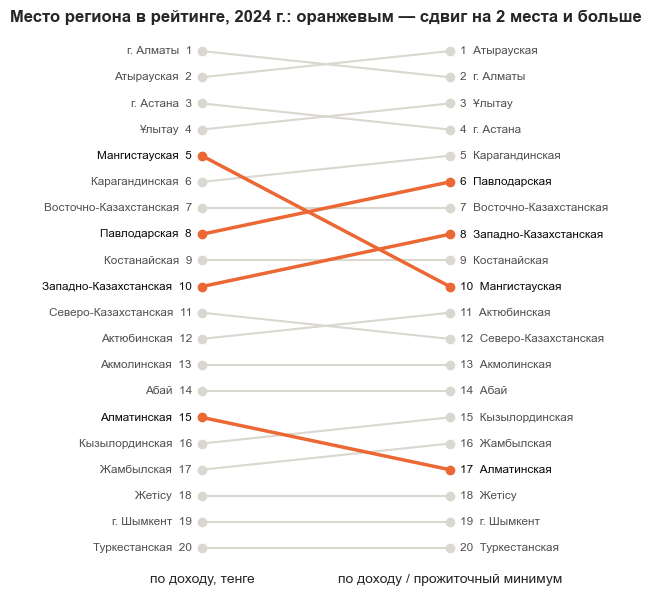

,region,income_pc,subsistence,income_to_subsistence,место по доходу,место по доходу/ПМ,сдвиг
105,Мангистауская,260252.0,62591.75,4.158,5,10,-5
32,Алматинская,154919.0,52151.75,2.971,15,17,-2
128,Северо-Казахстанская,194843.0,50010.00,3.896,11,12,-1
158,г. Астана,303175.0,55385.50,5.474,3,4,-1
168,г. Алматы,344454.0,54494.50,6.321,1,2,-1
22,Актюбинская,191514.0,46358.00,4.131,12,11,1
42,Атырауская,329734.0,48292.25,6.828,2,1,1
62,Жамбылская,150627.0,48134.75,3.129,17,16,1
75,Карагандинская,233677.0,49062.50,4.763,6,5,1
95,Кызылординская,153751.0,45858.25,3.353,16,15,1


In [6]:
r = regions[regions.year == LAST].copy()
r["место по доходу"] = r.income_pc.rank(ascending=False).astype(int)
r["место по доходу/ПМ"] = r.income_to_subsistence.rank(ascending=False).astype(int)
r["сдвиг"] = r["место по доходу"] - r["место по доходу/ПМ"]

rho_rank, _ = stats.spearmanr(r.income_pc, r.income_to_subsistence)
print(f"Доход различается в {r.income_pc.max() / r.income_pc.min():.1f} раза, "
      f"прожиточный минимум — в {r.subsistence.max() / r.subsistence.min():.2f} раза "
      f"(от {r.subsistence.min() / 1000:.1f} до {r.subsistence.max() / 1000:.1f} тыс. тенге)")
print(f"Совпадение рейтингов (Спирмен): ρ = {rho_rank:.2f}; регионов, сменивших место: {(r['сдвиг'] != 0).sum()} из {len(r)}")

fig, ax = plt.subplots(figsize=(8, 7))
for _, row in r.iterrows():
    moved = abs(row["сдвиг"]) >= 2
    color = ORANGE if moved else LIGHT
    ax.plot([0, 1], [row["место по доходу"], row["место по доходу/ПМ"]], color=color, lw=2.5 if moved else 1.5,
            marker="o", ms=6, zorder=3 if moved else 2)
    ax.text(-0.04, row["место по доходу"], f"{row.region}  {int(row['место по доходу'])}", ha="right", va="center",
            fontsize=8.5, color=INK if moved else MUTED)
    ax.text(1.04, row["место по доходу/ПМ"], f"{int(row['место по доходу/ПМ'])}  {row.region}", ha="left", va="center",
            fontsize=8.5, color=INK if moved else MUTED)
ax.set_ylim(20.8, 0.2)
ax.set_xlim(-0.75, 1.75)
ax.set_xticks([0, 1], ["по доходу, тенге", "по доходу / прожиточный минимум"])
ax.set_yticks([])
ax.grid(False)
for side in ["left", "bottom"]:
    ax.spines[side].set_visible(False)
ax.set_title(f"Место региона в рейтинге, {LAST} г.: оранжевым — сдвиг на 2 места и больше")
fig.savefig(IMAGES / "09_rank_nominal_vs_real.png", dpi=150, bbox_inches="tight")
plt.show()

r.loc[r["сдвиг"] != 0, ["region", "income_pc", "subsistence", "income_to_subsistence", "место по доходу",
                         "место по доходу/ПМ", "сдвиг"]].sort_values("сдвиг")

**H4 не подтверждается.** Рейтинги почти совпадают (ρ = 0,97). Причина простая: прожиточный минимум различается между регионами всего в 1,37 раза (45,8–62,6 тыс. тенге), а доходы — в 2,8 раза. Поправка на ПМ не может перевернуть картину. Города **не** теряют преимущество: Алматы и Астана опускаются лишь на одно место.

Исключение — **Мангистауская область**: она теряет 5 мест (5-е → 10-е), потому что прожиточный минимум там самый высокий в стране (62,6 тыс., на четверть выше медианы). Это не город, а нефтяной регион: высокие доходы там во многом «съедаются» ценами. Вероятная причина — удалённость и завоз продуктов, но это предположение, в данных его не проверить.

Ограничение: прожиточный минимум — грубая мера цен. В нём не учтена стоимость жилья, а именно аренда в Алматы и Астане дороже всего. Поэтому H4 нельзя окончательно отвергнуть — её нельзя подтвердить на доступных данных.

<a id="qol"></a>
## 5. Индекс качества жизни

Доход — не всё. Сводный индекс объединяет 6 показателей 2024 г. по 20 регионам:

| Компонент | Показатель | Направление |
|---|---|---|
| Деньги | доход / прожиточный минимум | больше — лучше |
| Бедность | доля с доходами ниже ПМ | меньше — лучше |
| Здоровье | ожидаемая продолжительность жизни | больше — лучше |
| Медицина | врачи на 10 тыс. | больше — лучше |
| Качество работы | доля неформально занятых | меньше — лучше |
| Привлекательность | сальдо миграции на 1000 («голосование ногами») | больше — лучше |

Каждый показатель приводится к шкале 0–100 (min-max: худший регион = 0, лучший = 100), индекс — среднее с равными весами. Равные веса — это выбор аналитика, поэтому ниже проверяем, насколько рейтинг от него зависит.

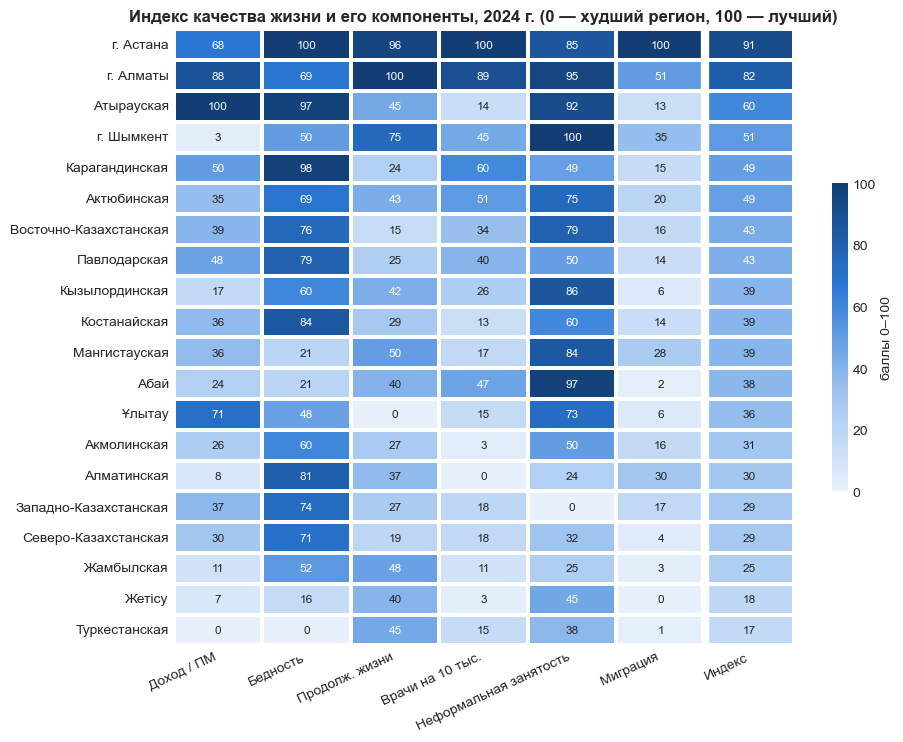

Связь индекса с доходом: ρ = 0.61 (p = 0.004)


In [7]:
COMPONENTS = {
    "income_to_subsistence": ("Доход / ПМ", +1),
    "poverty": ("Бедность", -1),
    "life_expectancy": ("Продолж. жизни", +1),
    "doctors_per10k": ("Врачи на 10 тыс.", +1),
    "informal_share": ("Неформальная занятость", -1),
    "migration_per1000": ("Миграция", +1),
}
X = r.set_index("region")[list(COMPONENTS)]
direction = pd.Series({c: s for c, (_, s) in COMPONENTS.items()})

def minmax(df):
    signed = df * direction
    return (signed - signed.min()) / (signed.max() - signed.min()) * 100

scores = minmax(X)
qol = scores.mean(axis=1).sort_values(ascending=False).rename("индекс")

table = scores.loc[qol.index].rename(columns={c: n for c, (n, _) in COMPONENTS.items()})
table["Индекс"] = qol

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(table, cmap=SEQ, vmin=0, vmax=100, annot=True, fmt=".0f", annot_kws={"size": 8.5},
            linewidths=1.5, linecolor="white", cbar_kws={"shrink": 0.5, "label": "баллы 0–100"}, ax=ax)
ax.axvline(len(COMPONENTS), color="white", lw=6)
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_title(f"Индекс качества жизни и его компоненты, {LAST} г. (0 — худший регион, 100 — лучший)")
plt.xticks(rotation=25, ha="right")
fig.savefig(IMAGES / "10_qol_index.png", dpi=150, bbox_inches="tight")
plt.show()

rho_qi, p_qi = stats.spearmanr(qol, r.set_index("region").loc[qol.index, "income_pc"])
print(f"Связь индекса с доходом: ρ = {rho_qi:.2f} (p = {p_qi:.3f})")

**Проверка устойчивости рейтинга.** Три способа поменять «правила игры»:
1. **Без одного компонента** — убираем по очереди каждый из шести;
2. **Случайные веса** — 2000 наборов весов (распределение Дирихле), каждый компонент может весить от 0 до 100%;
3. **Ранговая шкала вместо min-max** — min-max чувствителен к выбросам (сальдо миграции Астаны +51 на 1000 при медиане −6 сжимает всех остальных у нуля).

In [8]:
base_rank = qol.rank(ascending=False)
loo = pd.DataFrame({f"без «{n}»": scores.drop(columns=c).mean(axis=1).rank(ascending=False)
                    for c, (n, _) in COMPONENTS.items()})

rng = np.random.default_rng(42)
weights = rng.dirichlet(np.ones(len(COMPONENTS)), size=2000)
mc_ranks = pd.DataFrame(scores.values @ weights.T, index=scores.index).rank(ascending=False)

rank_scale = ((X * direction).rank() - 1) / (len(X) - 1) * 100
rank_alt = rank_scale.mean(axis=1).rank(ascending=False)

robust = pd.DataFrame({
    "индекс": qol.round(1),
    "место": base_rank.astype(int),
    "без одного компонента: мин–макс": [f"{int(loo.loc[i].min())}–{int(loo.loc[i].max())}" for i in qol.index],
    "случайные веса: 90% интервал": [f"{int(mc_ranks.loc[i].quantile(0.05))}–{int(mc_ranks.loc[i].quantile(0.95))}" for i in qol.index],
    "ранговая шкала": rank_alt.loc[qol.index].astype(int),
}, index=qol.index)
print(f"Совпадение с ранговой шкалой: ρ = {stats.spearmanr(base_rank, rank_alt.loc[base_rank.index])[0]:.2f}")
robust

Совпадение с ранговой шкалой: ρ = 0.97


,индекс,место,без одного компонента: мин–макс,случайные веса: 90% интервал,ранговая шкала
region,,,,,
г. Астана,91.5,1,1–1,1–2,1
г. Алматы,82.0,2,2–2,1–2,2
Атырауская,60.0,3,3–4,2–7,3
г. Шымкент,51.4,4,3–7,3–13,4
Карагандинская,49.4,5,4–8,3–11,6
Актюбинская,49.0,6,5–5,4–8,5
Восточно-Казахстанская,43.3,7,6–9,6–13,8
Павлодарская,42.5,8,7–11,5–13,9
Кызылординская,39.4,9,8–13,7–15,11


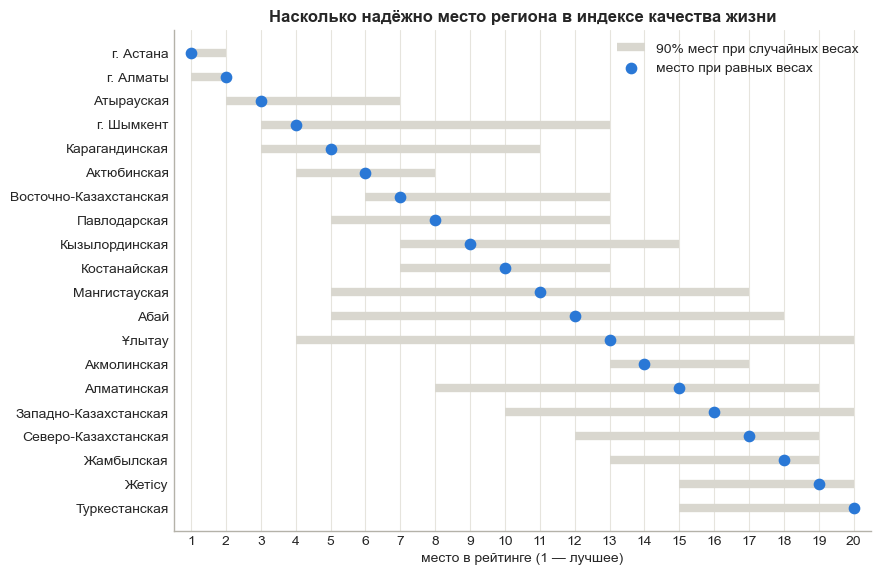

In [9]:
lo = mc_ranks.quantile(0.05, axis=1).loc[qol.index]
hi = mc_ranks.quantile(0.95, axis=1).loc[qol.index]
yy = np.arange(len(qol))

fig, ax = plt.subplots(figsize=(9, 6.5))
ax.hlines(yy, lo, hi, color=LIGHT, lw=6, zorder=1, label="90% мест при случайных весах")
ax.scatter(base_rank, yy, color=BLUE, s=55, zorder=3, label="место при равных весах")
ax.set_yticks(yy, qol.index)
ax.invert_yaxis()
ax.set_xticks(range(1, 21))
ax.set_xlim(0.5, 20.5)
ax.set_xlabel("место в рейтинге (1 — лучшее)")
ax.set_title("Насколько надёжно место региона в индексе качества жизни")
ax.grid(axis="y", visible=False)
ax.legend(frameon=False, loc="upper right")
fig.savefig(IMAGES / "11_qol_robustness.png", dpi=150, bbox_inches="tight")
plt.show()

**Вывод по индексу:**
- **Устойчиво лучшие — Астана и Алматы** (1–2 место при любых весах), затем Атырауская (2–7). Мегаполисы выигрывают сразу по всем компонентам: доходы, медицина, продолжительность жизни, приток людей.
- **Устойчиво худшие — Жетісу и Туркестанская** (15–20 место в 90% вариантов весов), рядом Жамбылская (13–19): низкие доходы, высокая бедность и неформальная занятость, отток населения.
- **Середина рейтинга неустойчива.** Например, Ұлытау может оказаться и на 4-м, и на 20-м месте в зависимости от весов: там высокие доходы, но самая короткая жизнь и отток людей. Для середины важен не номер места, а профиль по компонентам (тепловая карта выше).
- **Индекс связан с доходом лишь умеренно** (ρ = 0,61): деньги объясняют качество жизни только частично. Шымкент — 19-й по доходу, но 4-й по индексу благодаря продолжительности жизни, низкой неформальной занятости и притоку населения.
- Ранговая шкала вместо min-max даёт почти тот же рейтинг (ρ = 0,97), значит, выброс Астаны по миграции не исказил результат.

<a id="save"></a>
## 6. Сохранение метрик

Метрики понадобятся на этапах 7–8 (проверка гипотез и дашборд).

In [10]:
growth.to_csv(DATA / "metrics_cagr_units.csv", encoding="utf-8-sig")
sigma.to_csv(DATA / "metrics_sigma_convergence.csv", encoding="utf-8-sig")
qol_out = (table.join(robust[["место", "случайные веса: 90% интервал"]])
           .join(r.set_index("region")[["name_en", "income_pc"]]))
qol_out.to_csv(DATA / "metrics_qol_index.csv", encoding="utf-8-sig")
print("Сохранено: metrics_cagr_units.csv, metrics_sigma_convergence.csv, metrics_qol_index.csv")

Сохранено: metrics_cagr_units.csv, metrics_sigma_convergence.csv, metrics_qol_index.csv


<a id="summary"></a>
## 7. Выводы этапа

1. **Неравенство между регионами сокращается (H3 подтверждается).** Коэффициент вариации доходов снизился с 39,7% до 28,7%, разрыв между крайними регионами — с 3,6 до 2,7 раза. Бедные в 2015 г. регионы росли быстрее (r = −0,73). Но с учётом численности населения сближение с 2020 г. остановилось: мегаполисы держат отрыв.
2. **Реальный рост доходов скромный: от −0,4% до +4% в год** против 10–16% номинально. В Астане покупательная способность за 9 лет не выросла.
3. **Поправка на прожиточный минимум почти не меняет рейтинг (H4 не подтверждается):** ПМ различается в 1,4 раза, доходы — в 2,8. Исключение — Мангистауская обл., теряет 5 мест из-за самого высокого ПМ в стране. Цены на жильё в ПМ не учтены — это ограничение данных.
4. **Индекс качества жизни лишь частично совпадает с доходом** (ρ = 0,61). Надёжно лучшие — Астана и Алматы, надёжно худшие — Жетісу и Туркестанская, рядом Жамбылская. Именно эти три южных региона — первые кандидаты на программы развития.

**Что это значит для заказчика:** программы развития имеет смысл нацеливать на устойчиво отстающий юг (Жетісу, Туркестанская, Жамбылская), а не на «средние» регионы, чьё место в рейтинге зависит от выбора весов. Для Мангистауской области вопрос не столько в доходах, сколько в стоимости жизни.